## **Coding 10đ**

* import thư viện

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### **Discovery & Structuring (1.9đ)**


* đọc file csv, in 3 dòng cuối tiên (0.2đ)


In [ ]:
# file ko có dữ liệu nên chưa chạy được, chỉ tham khảo

In [ ]:
df = pd.read_csv("postings.csv", low_memory=False) # low_memory=False: giúp Pandas đọc dữ liệu mà không suy luận kiểu dữ liệu theo từng phần nhỏ
df.head(3)

In [ ]:
df.tail(3)

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
123851,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
123852,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
123853,35982263,NaN,Service Technician (duplicate job_id),Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


* đọc thông tin data (0.15đ)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123854 entries, 0 to 123853
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123854 non-null  int64  
 1   company_name                122133 non-null  object 
 2   title                       123854 non-null  object 
 3   description                 123847 non-null  object 
 4   max_salary                  29798 non-null   float64
 5   pay_period                  36078 non-null   object 
 6   location                    123854 non-null  object 
 7   company_id                  122135 non-null  float64
 8   views                       122165 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29798 non-null   float64
 11  formatted_work_type         123854 non-null  object 
 12  applies                     23321 non-null   float64
 13  original_liste

* in thông tin số dòng và số cột (0.15đ)

In [ ]:
print(df.shape[0]) #dòng
print(df.shape[1]) #cột

123854
31


* in ra các giá trị formatted_work_type trong bộ data (0.15đ)

In [ ]:
print(df["formatted_work_type"].unique())

['Full-time' 'Internship' 'Contract' 'Part-time' 'Temporary' 'Volunteer'
 'Other']


* đổi tên cột normalized_salary --> salary và formatted_experience_level --> experience_level (0.2đ)

In [ ]:
df = df.rename(columns={
    "normalized_salary": "salary",
    "formatted_experience_level": "experience_level"
})

* in lại danh sách các cột sau khi rename (0.15đ)

In [ ]:
print(df.columns.tolist())

['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'salary', 'zip_code', 'fips']


* Tạo dataframe df_profile bao gồm dtype, nunique, missing_count, missing_percentage. Sắp xếp giảm dần theo missing_percentage. (0.5đ)


In [ ]:
# cách 1:
dtype = df.dtypes
nunique = df.nunique()
missing_count = df.isnull().sum()
missing_percentage = df.isnull().mean() * 100

df_profile = pd.DataFrame({
    'dtype': dtype,
    'nunique': nunique,
    'missing_count': missing_count,
    'missing_percentage': missing_percentage
})

df_profile = df_profile.sort_values(
    by='missing_percentage', ascending=False
)

print(df_profile)

In [ ]:
# cách 2 (lạ): 
df_profile = pd.DataFrame({
    'dtype': df.dtypes,
    'nunique': df.nunique(),
    'missing_count': df.isnull().sum(),
    'missing_percentage': df.isnull().mean() * 100
})

df_profile = df_profile.sort_values(
    by='missing_percentage',
    ascending=False
)

print(df_profile)

,dtype,nunique,missing_count,missing_percentage
closed_time,float64,698,122781,99.133657
skills_desc,object,2212,121412,98.028324
med_salary,float64,1417,117574,94.929514
remote_allowed,float64,1,108608,87.690345
applies,float64,274,100533,81.170572
max_salary,float64,5321,94056,75.941027
min_salary,float64,4612,94056,75.941027
currency,object,6,87776,70.870541
compensation_type,object,1,87776,70.870541
salary,float64,7259,87776,70.870541


* tìm số dòng thỏa điều kiện formatted_work_type là Full-time và salary từ 100000 trở lên (0.2đ)

In [ ]:
# cách 1:
((df['formatted_work_type'] == 'Full-time') & (df['salary'] >= 100000)).sum()

In [ ]:
# cách 2 (lạ):
condition = (df["formatted_work_type"] == "Full-time") & (df["salary"] >= 100000)
print("Số dòng Full-time có salary từ 100000 trở lên:", condition.sum())

Số dòng Full-time có salary từ 100000 trở lên: 11702


* cho biết số dòng có remote_allowed bằng 1 và application_type là OffsiteApply (0.2đ)

In [ ]:
# cách 1:
((df['remote_allowed'] == 1) & (df['application_type'] == 'OffsiteApply')).sum()

In [ ]:
# cách 2 (lạ):
condition = (df["remote_allowed"] == 1) & (df["application_type"] == "OffsiteApply")
print("Số dòng remote_allowed = 1 và application_type = OffsiteApply:", condition.sum())

Số dòng remote_allowed = 1 và application_type = OffsiteApply: 7283


### **Cleaning**

#### **Duplicated & missing data (3.05đ)**


Duplicate count (0.4đ)
* In số dòng trùng cả bản ghi.
* In số job_id bị lặp.


In [ ]:
df.duplicated().sum() #In số dòng trùng cả bản ghi

In [ ]:
df['job_id'].duplicated().sum() #In số job_id bị lặp

In [ ]:
# cách 2 (lạ):
print("Số dòng trùng toàn bộ bản ghi:", df.duplicated().sum())
print("Số dòng có job_id bị lặp :",
      df["job_id"].duplicated().sum())
print("Số job_id khác nhau bị lặp:",
      df.loc[df["job_id"].duplicated(keep=False), "job_id"].nunique())

Số dòng trùng toàn bộ bản ghi: 3
Số dòng có job_id bị lặp : 5
Số job_id khác nhau bị lặp: 5


* xoá số dòng duplicated cả bản ghi (0.25đ)


In [ ]:
# cách 1: 
df = df.drop_duplicates() #xóa trùng
df.duplicated().sum() #kt lại

In [ ]:
# cách 2 (lạ):
df = df.drop_duplicates()
df.shape

(123851, 31)

* xoá số dòng duplicated số job_id (0.25đ)


In [ ]:
# cách 1: 
df = df.drop_duplicates(subset=['job_id']) 
df['job_id'].duplicated().sum()

In [ ]:
# cách 2 (lạ):
df = df.drop_duplicates(subset=["job_id"])
df.shape

(123849, 31)

df2 missing table (0.4đ)
* Kiểm tra dữ liệu có missing không?
* Nếu có, tạo df2 gồm 3 cột: column_name, missing_count, missing_percentage
* Sắp xếp df2 giảm dần theo missing_count
* Chỉ giữ các dòng có missing_count khác 0

In [ ]:
# cách 1:
missing_count = df.isna().sum()  # đếm số lượng giá trị missing
missing_percentage = df.isna().mean() * 100  # %

df2 = pd.DataFrame({
    'column_name': df.columns,
    'missing_count': missing_count,
    'missing_percentage': missing_percentage
})

df2 = df2[df2['missing_count'] != 0] #kt cột missing_count, chỉ lấy những dòng có gtrị khác 0
df2 = df2.sort_values(by='missing_count', ascending=False) #(sắp xếp theo cột missing_count, giảm dần)

df2

In [ ]:
# cách 2 (lạ):
missing_count = df.isna().sum()
df2 = pd.DataFrame({
    "column_name": missing_count.index,
    "missing_count": missing_count.values,
    "missing_percentage": df.isna().mean().mul(100).values
})
df2 = (df2[df2["missing_count"] != 0]
       .sort_values("missing_count", ascending=False)
       .reset_index(drop=True))
df2

,column_name,missing_count,missing_percentage
0,closed_time,122776,99.133622
1,skills_desc,121410,98.030666
2,med_salary,117569,94.929309
3,remote_allowed,108603,87.689848
4,applies,100529,81.170619
5,max_salary,94056,75.944093
6,min_salary,94056,75.944093
7,pay_period,87776,70.873402
8,salary,87776,70.873402
9,compensation_type,87776,70.873402


Missing-value bar chart (0.4đ)
* Sử dụng barchart để vẽ df2 với x là missing_count, y là column_name. Trong đó xlabel là số lượng thiếu, ylabel là tên cột

In [ ]:
df2.plot(kind='bar', x='column_name', y='missing_count')

plt.xlabel('Số lượng thiếu')
plt.ylabel('Tên cột')
plt.show()

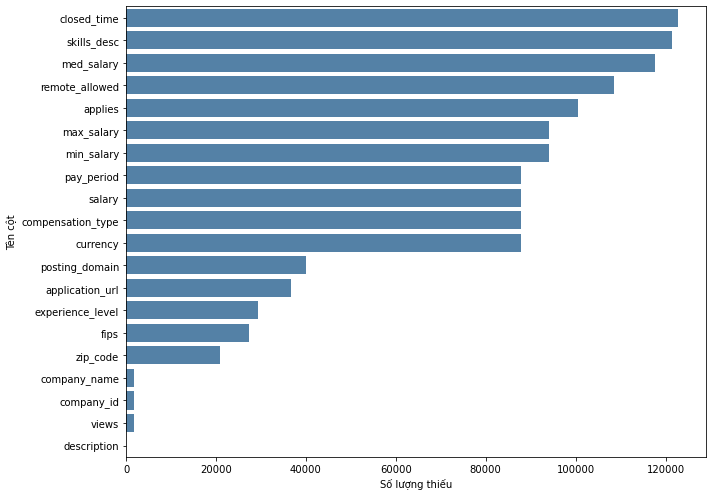

In [ ]:
# cách 2 (lạ):
if not df2.empty:
    plt.figure(figsize=(10, max(4, 0.35 * len(df2))))
    sns.barplot(data=df2, x="missing_count", y="column_name", color="steelblue")
    plt.xlabel("Số lượng thiếu")
    plt.ylabel("Tên cột")
    plt.tight_layout()
    plt.show()
else:
    print("Không có giá trị thiếu trong dữ liệu.")

* tạo ra 1 cột salary_missing, nếu salary bị thiếu thì bằng 1, ngược lại bằng 0, gợi ý isna() (0.25đ)


In [ ]:
df["salary_missing"] = df["salary"].isna().astype(int)
# astype(int): chuyển True thành 1, False thành 0

In [ ]:
# hoặc dùng cách này để chuyển về 0-1
df['salary_missing'] = df['salary'].isna() * 1

* salary_missing_by_work = Nhóm theo formatted_work_type, tính mean của cột salary_missing rồi nhân 100 để ra tỷ lệ thiếu (%). Sắp xếp tăng dần và đổi tên thành salary_missing_pct. (0.25đ)


In [ ]:
salary_missing_by_work = df.groupby('formatted_work_type')['salary_missing'].mean() * 100
salary_missing_by_work = salary_missing_by_work.sort_values(ascending=True)
salary_missing_by_work = salary_missing_by_work.rename('salary_missing_pct')
# Nhóm theo loại công việc, tính tỷ lệ thiếu (%)
# Sắp xếp 'tỷ lệ thiếu' tăng dần
# Đổi tên thành 'salary_missing_pct'

In [ ]:
# cách 2 (lạ):
salary_missing_by_work = (
    df.groupby("formatted_work_type", dropna=False)["salary_missing"]
      .mean()
      .mul(100)
      .sort_values(ascending=True)
      .rename("salary_missing_pct")
      .reset_index()
)
salary_missing_by_work

,formatted_work_type,salary_missing_pct
0,Temporary,66.890756
1,Contract,68.234712
2,Full-time,70.517336
3,Other,71.663244
4,Internship,74.872838
5,Part-time,76.237624
6,Volunteer,98.576512


* Vẽ bar chart tỷ lệ thiếu salary theo formatted_work_type. xlabel là tỷ lệ thiếu (%), ylabel là tên nhóm. (0.25đ)


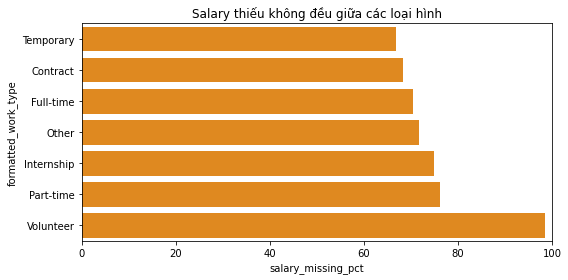

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=salary_missing_by_work,
    x="salary_missing_pct",
    y="formatted_work_type",
    color="darkorange",
)
plt.title("Salary thiếu không đều giữa các loại hình")
plt.xlim(0, 100) #đặt giới hạn trục X từ 0 đến 100
plt.tight_layout() #giúp tự động căn chỉnh biểu đồ, tránh tiêu đề, nhãn trục hoặc chữ bị chồng lên nhau hay bị cắt.
plt.show()

Fill with mode/mean/median (0.6đ)
* company_name: điền mode.
* views và applies: điền median.
* experience_level: ô trống điền nhãn Unknown.
* Tạo remote_flag từ remote_allowed, ô trống điền 0.
* salary: không điền.


In [ ]:
df['company_name'] = df['company_name'].fillna(df['company_name'].mode()[0]) #mode()[0]: lấy gtrị xuất hiện nhiều nhất

df['views'] = df['views'].fillna(df['views'].median()) #tính trung vị của cột views
df['applies'] = df['applies'].fillna(df['applies'].median())

df['experience_level'] = df['experience_level'].fillna('Unknown') #Điền chữ 'Unknown' vào các ô thiếu của cột experience_level

df['remote_flag'] = df['remote_allowed'].fillna(0)
# Tạo cột mới remote_flag từ cột remote_allowed. Ô thiếu được điền bằng 0.

In [ ]:
# cách 2 (lạ):
if df["company_name"].notna().any():
    df["company_name"] = df["company_name"].fillna(df["company_name"].mode().iloc[0])

for col in ["views", "applies"]:
    df[col] = df[col].fillna(df[col].median())

df["experience_level"] = df["experience_level"].fillna("Unknown")
df["remote_flag"] = df["remote_allowed"].fillna(0)
# Không điền giá trị thiếu của salary.

In [ ]:
# kiểm tra lại sau xử lý missing data
df[["company_name", "views", "applies", "experience_level", "salary"]].isnull().sum()

company_name            0
views                   0
applies                 0
experience_level        0
salary              87776
dtype: int64

#### **Outlier (2.5đ)**

* df2_1 chỉ chứa views và salary. Hiển thị 2 dòng (0.2đ)


In [ ]:
df2_1 = df[['views', 'salary']]
df2_1.head(2)

In [ ]:
# cách 2 (lạ):
df2_1 = df[["views", "salary"]].copy()
df2_1.head(2)

,views,salary
0,20.0,38480.0
1,1.0,83200.0


df3 with concat (0.5đ)
* Tạo dataframe df3 bằng CONCAT
* df3 gồm các cột Q1, Q3, IQR, lower_bound, upper_bound, outlier_count
* Trong đó cột Q1 là 22%, Q3 = 78%

In [ ]:
Q1 = df['salary'].quantile(0.22)
Q3 = df['salary'].quantile(0.78)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outlier_count = ((df['salary'] < lower_bound) | (df['salary'] > upper_bound)).sum()

df3 = pd.concat([
    pd.Series({'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
               'lower_bound': lower_bound, 
               'upper_bound': upper_bound,
               'outlier_count': outlier_count
               })
], axis=1).T #.T là chuyển hàng thành cột, cột thành hàng (transpose)

df3

In [ ]:
# cách 2 (lạ):
stats = {}
for col in df2_1.columns:
    s = df2_1[col].dropna()
    q1 = s.quantile(0.22)
    q3 = s.quantile(0.78)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    stats[col] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": ((s < lower) | (s > upper)).sum()
    }

df3 = pd.DataFrame(stats).T
df3

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
views,3.0,8.00,5.00,-4.50,15.5,16902.0
salary,48880.0,130169.44,81289.44,-73054.16,252103.6,720.0


df4 outlier filter (0.4đ)
* df4 lọc lại dữ liệu, loại các dòng có ít nhất một cột số trong df2_1 nằm ngoài [lower_bound, upper_bound]

In [ ]:
df4 = df[~((df['views'] < lower_bound) | (df['views'] > upper_bound) |
           (df['salary'] < lower_bound) | (df['salary'] > upper_bound))]

In [ ]:
# cách 2 (lạ):
mask = pd.Series(True, index=df.index)
for col in df2_1.columns:
    lower = df3.loc[col, "lower_bound"]
    upper = df3.loc[col, "upper_bound"]
    mask &= df[col].isna() | df[col].between(lower, upper)

df4 = df.loc[mask].copy()


In [ ]:
df4.shape #Kiểm tra số dòng, số cột sau khi lọc.

(106379, 33)

df5 clip (0.3đ)
* Tạo df5 từ df bằng clip kéo ngưỡng về chặn trên chặn dưới

In [ ]:
df5 = df.copy()
df5['views'] = df5['views'].clip(lower=lower_bound, upper=upper_bound)
df5['salary'] = df5['salary'].clip(lower=lower_bound, upper=upper_bound)

In [ ]:
# hoặc:
df5 = df.copy()
df5[['views', 'salary']] = df5[['views', 'salary']].clip(lower_bound, upper_bound)

In [ ]:
# kt lại xem đk
print(df5[['views', 'salary']].min())
print(df5[['views', 'salary']].max())

In [ ]:
# cách 2 (lạ):
df5 = df.copy()
col = "views"
df5[col] = df5[col].clip(
    lower=df3.loc[col, "lower_bound"],
    upper=df3.loc[col, "upper_bound"]
)

col = "salary"
df5[col] = df5[col].clip(
    lower=df3.loc[col, "lower_bound"],
    upper=df3.loc[col, "upper_bound"]
)

Histogram of salary (0.25đ)
* vẽ histogram cho cột salary trong df4
* title là "phân phối salary"
* xlabel là "salary (USD/year)"

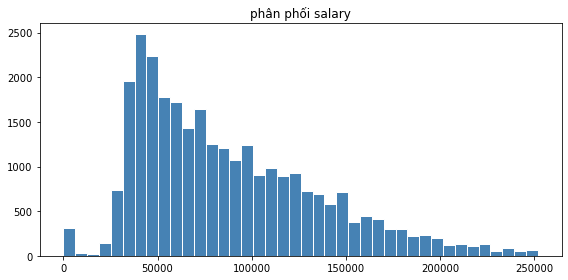

In [ ]:
plt.figure(figsize=(8, 4)) #rộng, cao
plt.hist(df4["salary"].dropna(), bins=40, color="steelblue", edgecolor="white")
# bins=40: chia dữ liệu thành 40 khoảng,edgecolor="white": màu viền cột trắng.

plt.title("phân phối salary")
plt.xlabel('salary (USD/year)')
plt.tight_layout()
plt.show()

Is salary skewed? Print skew, kurtosis, mean, median (0.6đ)
* Dùng cột salary của df4 (bỏ giá trị thiếu). Dữ liệu có lệch không? In ra skew, kurtosis, mean, median.
* Từ kurtosis, so với phân phối chuẩn thì đỉnh nhọn hơn hay hai đuôi dày hơn?

In [ ]:
salary = df4['salary'].dropna()

print('Skew:', salary.skew())
print('Kurtosis:', salary.kurt())
print('Mean:', salary.mean())
print('Median:', salary.median())

# Skew: > 0 lệch phải, < 0 lệch trái, gần 0 thì tương đối đối xứng.
# Kurtosis: # > 0 đỉnh nhọn hơn và đuôi dày hơn phân phối chuẩn; 
            # < 0 đỉnh bẹt hơn và đuôi mỏng hơn; 
            # = 0 tương đương phân phối chuẩn về độ nhọn (excess kurtosis).

In [ ]:
# cách 2 (lạ);
salary_clean = df4["salary"].dropna()
print("salary skew:", salary_clean.skew())
print("salary kurtosis:", salary_clean.kurt())
print("salary mean:", salary_clean.mean())
print("salary median:", salary_clean.median())

salary skew: 0.8899689932377013
salary kurtosis: 0.31863979137135034
salary mean: 87343.70006426182
salary median: 75400.0


Gợi ý trả lời (tự điền theo số vừa in, không chép kết luận):

1. Xem dấu của skew. skew > 0 thì lệch phải, đuôi về phía giá trị lớn; skew < 0 thì lệch trái. Đối chiếu mean với median: bên nào lớn hơn thì đuôi kéo về bên đó.

2. kurtosis của pandas là excess kurtosis. Phân phối chuẩn có excess kurtosis bằng 0. Số vừa in > 0 thì đỉnh nhọn hơn và hai đuôi dày hơn chuẩn; < 0 thì đỉnh phẳng hơn và hai đuôi mỏng hơn chuẩn.

1. Nhận xét:
- Skewness = 0.89 > 0: Phân phối lệch phải .
- Mean = 87,343.70 > Median = 75,400: dấu hiệu phân phối lệch phải.
2. Kurtosis = 0.32 > 0: đỉnh nhọn hơn và hai đuôi dày hơn chuẩn

Create salary_log with np.log (0.25đ)

* Tạo cột salary_log trong df4 bằng np.log.
* salary không dương thì salary_log để NaN.
* Gợi ý: tạo cột salary_log toàn NaN trước. Dùng .loc với điều kiện salary > 0 rồi mới gán np.log. np.log chỉ nhận số dương.


In [ ]:
df4['salary_log'] = np.nan #Tạo cột salary_log, ban đầu tất cả giá trị đều là NaN

condition = df4['salary'] > 0 #chọn dòng có salary > 0.
salary_positive = df4['salary'][condition] #lấy salary của những dòng đã chọn (Chỉ lấy những giá trị salary có condition = True)

salary_log = np.log(salary_positive) # np.log(...): tính log.
df4.loc[condition, 'salary_log'] = salary_log # .loc: gán kết quả vào salary_log.
# dòng cuối là: lấy "đáp án đúng" của condition chọn, ròi qua salary_log chọn "giá trị" của "đáp án đúng" đó, ròi gán "giá trị" đó vào

In [ ]:
# Cách 2 (lạ):
df4["salary_log"] = np.nan
positive_salary = df4["salary"] > 0
df4.loc[positive_salary, "salary_log"] = np.log(df4.loc[positive_salary, "salary"])

### **Univariate Analysis (0.55đ)**


* thống kê mô tả cho 2 cột salary và salary_log trong df4 (0.3đ)

In [ ]:
df4[["salary", "salary_log"]].describe()

,salary,salary_log
count,28944.000000,28935.000000
mean,87343.700064,11.169737
std,48167.177633,0.926489
min,0.000000,0.000000
25%,48599.200000,10.792526
50%,75400.000000,11.231881
75%,117083.750000,11.671125
max,252000.000000,12.437184


* In skew, kurtosis, mean, median của salary_log. Vẽ hai histogram cạnh nhau: salary và salary_log. (0.25đ)


In [ ]:
salary_log = df4['salary_log'].dropna()

print('Skew:', salary_log.skew())
print('Kurtosis:', salary_log.kurt())
print('Mean:', salary_log.mean())
print('Median:', salary_log.median())

plt.figure(figsize=(10, 4))

# plt.subplot(số_hàng, số_cột, vị_trí)
plt.subplot(1, 2, 1) # Vẽ histogram salary bên trái
plt.hist(df4['salary'].dropna(), bins=40)
plt.title('salary')

plt.subplot(1, 2, 2) # Vẽ histogram salary_log bên phải
plt.hist(df4['salary_log'].dropna(), bins=40)
plt.title('salary_log')

plt.tight_layout()
plt.show()

salary_log skew: -5.303350463976039
salary_log kurtosis: 41.78904703202538
salary_log mean: 11.169737248739809
salary_log median: 11.231881180247413


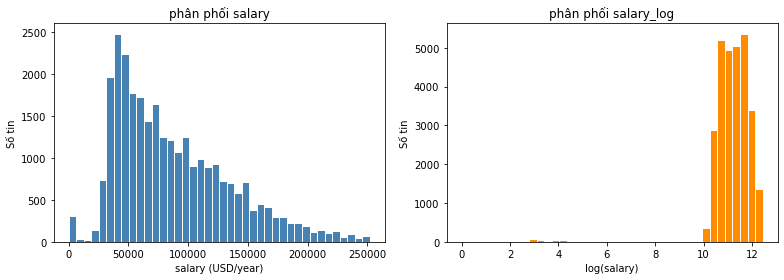

In [ ]:
# Cách 2 (lạ):
salary_log_clean = df4["salary_log"].dropna()
print("salary_log skew:", salary_log_clean.skew())
print("salary_log kurtosis:", salary_log_clean.kurt())
print("salary_log mean:", salary_log_clean.mean())
print("salary_log median:", salary_log_clean.median())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df4["salary"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("phân phối salary")
axes[0].set_xlabel("salary (USD/year)")
# salary_log tương tự salary
# axes[1].
axes[1].hist(df4["salary_log"].dropna(), bins=40, color="darkorange", edgecolor="white")
axes[1].set_title("phân phối salary_log")
axes[1].set_xlabel("log(salary)")

for ax in axes:
    ax.set_ylabel("Số tin")

plt.tight_layout()
plt.show()

### **Bivariate & Multivariate Analysis (1.65đ)**

Xem mối quan hệ giữa các biến.

* Heatmap (0.3đ): Correlation heatmap giữa các cột số, bao gồm views, applies, min_salary, max_salary, med_salary, salary.

In [ ]:
cols = ['views', 'applies', 'min_salary', 'max_salary', 'med_salary', 'salary']
# nếu đề ko cho những cột nào thì dùng hàm này: 
# cols = df.select_dtypes(include='number').columns

corr = df[cols].corr() #tính tương quan (đề yêu cầu)

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

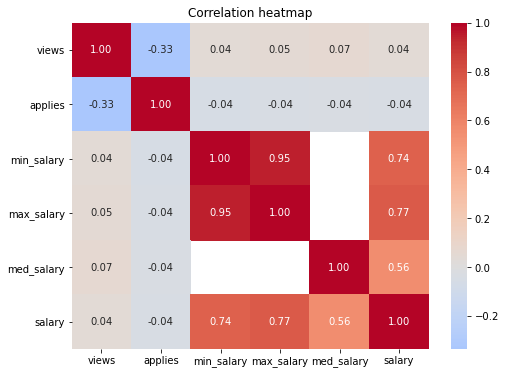

In [ ]:
# Cách 2: ko biết phải của cô ko 
numeric_cols = ["views", "applies", "min_salary",
                "max_salary", "med_salary", "salary"]

corr = df4[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

# annot=True: hiển thị số tương quan trong từng ô.
# fmt=".2f": hiển thị số với 2 chữ số thập phân, ví dụ 0.85.
# cmap="coolwarm": dùng màu lạnh và nóng để biểu thị mức tương quan.
# center=0: lấy giá trị 0 làm trung tâm màu, giúp phân biệt tương quan âm và dương.

* df4 group by theo formatted_work_type, tính count, mean, median của salary (0.3đ), gợi ý: .agg([count,...])


In [ ]:
df4.groupby('formatted_work_type')['salary'].agg(['count', 'mean', 'median']) 
# nhóm theo loại công việc, lấy cột lương, ròi tính cùng lúc
# agg(...): dùng để tính nhiều phép thống kê cùng lúc

In [ ]:
# Cách 2 (lạ):
salary_by_work = (
    df4.groupby("formatted_work_type")["salary"]
       .agg(["count", "mean", "median"])
       .sort_values("median", ascending=False)
)
salary_by_work

,count,mean,median
formatted_work_type,,,
Contract,2383,93057.385898,88400.0
Full-time,23765,90175.523295,78830.0
Other,127,71667.789449,57200.0
Temporary,336,67628.729167,54437.4
Internship,166,50868.809880,44720.0
Part-time,2160,56893.214468,41600.0
Volunteer,7,20052.142857,0.0


* df4 group by theo experience_level, tính count, mean, median của salary. (0.5đ)


In [ ]:
df4.groupby('experience_level')['salary'].agg(['count', 'mean', 'median'])

In [ ]:
# Cách 2 (lạ):
salary_by_experience = (
    df4.groupby("experience_level")["salary"]
       .agg(["count", "mean", "median"])
       .sort_values("median", ascending=False)
)
salary_by_experience

,count,mean,median
experience_level,,,
Director,846,158042.997051,158825.00
Executive,215,150374.566488,150000.00
Mid-Senior level,10077,105177.791091,102500.00
Unknown,6375,85392.553860,72644.00
Associate,2808,78453.061521,70971.25
Entry level,8324,62687.339458,51360.40
Internship,299,52446.171522,48880.00


* Tạo pivot median salary theo experience_level (hàng) và formatted_work_type (cột). Vẽ heatmap. (0.55đ). Gợi ý: dùng pivot_table, index là hàng, columns là cột, values, aggfunc gọi hàm. Sau đó vẽ heatmap


In [ ]:
pivot = df4.pivot_table(
    index='experience_level',
    columns='formatted_work_type',
    values='salary',
    aggfunc='median'
)

sns.heatmap(pivot, annot=True, fmt='.0f', cmap='coolwarm')
plt.show()

In [ ]:
# giải thích code bên dưới của cô:
# pivot_table(): tạo bảng tổng hợp, trong đó hàng và cột được chia theo nhóm.
# index="experience_level": dùng cấp độ kinh nghiệm làm hàng.
# columns="formatted_work_type": dùng loại hình công việc làm cột.
# values="salary": lấy dữ liệu lương để tính toán.
# aggfunc="median": nếu một nhóm có nhiều mức lương thì lấy trung vị của nhóm đó.
# annot=True: hiện số liệu trong từng ô heatmap.
# fmt=".0f": hiển thị số không có chữ số thập phân, ví dụ 50000.75 thành 50001

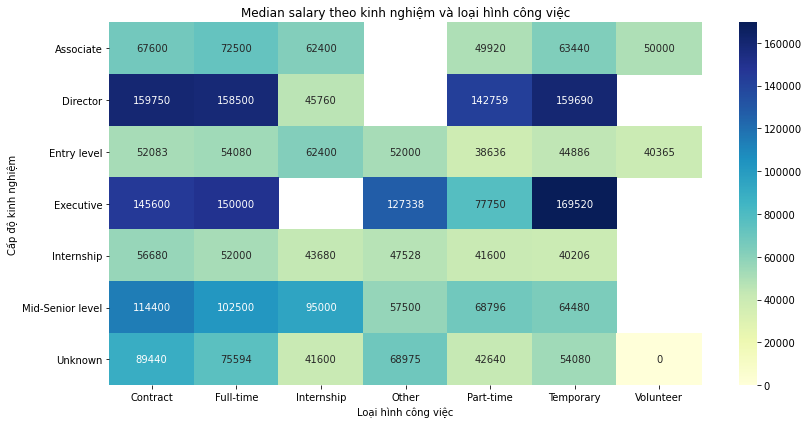

In [ ]:
# hình như cái này là gợi ý của cô
salary_pivot = df4.pivot_table(
    index="experience_level",
    columns="formatted_work_type",
    values="salary",
    aggfunc="median"
)

plt.figure(figsize=(12, 6))
sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Median salary theo kinh nghiệm và loại hình công việc")
plt.xlabel("Loại hình công việc")
plt.ylabel("Cấp độ kinh nghiệm")
plt.tight_layout()
plt.show()

### **Publishing (0.35đ)**

* Lưu df4 ra file Excel, đặt tên df4.xlsx (0.2đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [ ]:
df4.drop(columns=['description', 'skills_desc', 'job_posting_url', 'application_url']).to_excel('df4.xlsx', index=False)

In [ ]:
# Cách 2 (lạ):
exclude_cols = ["description", "skills_desc", "job_posting_url", "application_url"]
export_df = df4.drop(columns=exclude_cols, errors="ignore")
export_df.to_excel("df4.xlsx", index=False)
print("Đã lưu df4.xlsx")

Đã lưu df4.xlsx


* Sau đó lưu df4 ra file HTML, đặt tên df4.html (0.15đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [ ]:
df4.drop(columns=['description', 'skills_desc', 'job_posting_url', 'application_url']).to_html('df4.html', index=False)

In [ ]:
# Cách 2 (lạ):
exclude_cols = ["description", "skills_desc", "job_posting_url", "application_url"]
export_df = df4.drop(columns=exclude_cols, errors="ignore")
export_df.to_html("df4.html", index=False)
